# Clustering track: Starbucks menu nutrition

**Problem statement:** group Starbucks drinks into clusters using only their nutritional profile, with no labels used while fitting.

**Algorithms:** K-Means and Agglomerative Hierarchical Clustering
**Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index
**Visualisations:** Elbow curve, Dendrogram, PCA 2D scatter, t-SNE

> Dataset: Starbucks Menu (Kaggle, `starbucks/starbucks-menu`), file `starbucks_drinkMenu_expanded.csv`.
> Code scaffolding assisted by an AI tool (cite in the README); interpretation is the team's own.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("colorblind")   # colourblind-friendly


def cluster_metrics(X_, labels_):
    # Silhouette and Calinski-Harabasz: higher is better; Davies-Bouldin: lower is better
    return {"Silhouette": silhouette_score(X_, labels_),
            "Davies-Bouldin": davies_bouldin_score(X_, labels_),
            "Calinski-Harabasz": calinski_harabasz_score(X_, labels_)}


def plot_clusters(ax, coords, labels, title, xlabel, ylabel):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], s=35, alpha=0.8, color=PALETTE[c % len(PALETTE)],
                   edgecolor="white", linewidth=0.4, label=f"cluster {c} (n={m.sum()})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

## 1. load and audit the data

In [2]:
DATA_FILE = "starbucks_drinkMenu_expanded.csv"
path = next((p for p in [f"../data/{DATA_FILE}", f"data/{DATA_FILE}", DATA_FILE] if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"{DATA_FILE} not found. Put it in the data/ folder.")

raw = pd.read_csv(path)
print("shape:", raw.shape)
display(raw.head())
print("\ndtypes:")
print(raw.dtypes)
print("\nmissing values per column:")
print(raw.isna().sum())
print("\nduplicate rows:", raw.duplicated().sum())

FileNotFoundError: starbucks_drinkMenu_expanded.csv not found. Put it in the data/ folder.

## 2. cleaning

Tidy the column names, convert numeric columns that were read as text (`"10%"`, `"Varies"`), repair one typo (`"3 2"` -> `3.2`), correct mislabelled columns (2.1), and fill the remaining missing values with the median.

In [3]:
def tidy_name(c):
    c = re.sub(r"\(.*?\)", "", str(c))                   # drop units like (g), (mg), (% DV)
    return re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_")

df = raw.copy()
df.columns = [tidy_name(c) for c in df.columns]

numeric_cols = []
for col in df.columns:
    s = df[col].astype(str).str.replace("%", "", regex=False).str.strip()
    s = s.str.replace(r"^(\d+)\s+(\d+)$", r"\1.\2", regex=True)       # typo "3 2" -> "3.2"
    converted = pd.to_numeric(s, errors="coerce")                      # "Varies" becomes NaN
    if converted.notna().mean() >= 0.6:                                # mostly numeric -> clustering feature
        df[col] = converted
        numeric_cols.append(col)

print("features used for clustering:", numeric_cols)
n_missing = df[numeric_cols].isna().sum()
print("\nmissing after conversion:")
print(n_missing[n_missing > 0])

features used for clustering: ['calories', 'total_fat', 'trans_fat', 'saturated_fat', 'sodium', 'total_carbohydrates', 'cholesterol', 'dietary_fibre', 'sugars', 'protein', 'vitamin_a', 'vitamin_c', 'calcium', 'iron', 'caffeine']

missing after conversion:
caffeine    23
dtype: int64


### 2.1 column label check

In this CSV the header order does not match the data order. Two physical rules expose it: sugars can never exceed total carbohydrates, and trans fat can never exceed saturated fat. If they fail under the given labels, the labels are shifted and are corrected below.

In [3]:
bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
print(f"as labelled : sugars > carbs in {bad_sugar} rows, trans fat > saturated fat in {bad_fat} rows (both impossible)")

if bad_sugar > 0 or bad_fat > 0:
    # actual data order: saturated fat, trans fat, cholesterol, sodium, total carbohydrates
    df = df.rename(columns={"trans_fat": "saturated_fat", "saturated_fat": "trans_fat",
                            "sodium": "cholesterol", "total_carbohydrates": "sodium",
                            "cholesterol": "total_carbohydrates"})
    bad_sugar = int((df["sugars"] > df["total_carbohydrates"]).sum())
    bad_fat = int((df["trans_fat"] > df["saturated_fat"]).sum())
    print(f"after fixing: sugars > carbs in {bad_sugar} rows, trans fat > saturated fat in {bad_fat} rows")

df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())   # median is robust and uses no labels
print("clean feature matrix:", df[numeric_cols].shape)

NameError: name 'df' is not defined

**cleaning notes:** *(write your own: the mislabelled headers, the typo, how missing caffeine values were handled)*

## 3. scaling and PCA projection

K-Means and hierarchical clustering are distance-based, so features are standardised; otherwise sodium (mg) would dominate fat (g). PCA to 2 components is used only for plotting.

In [5]:
X_scaled = StandardScaler().fit_transform(df[numeric_cols].values)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"PC1 explains {evr[0]:.1%}, PC2 explains {evr[1]:.1%} of the variance")

PC1 explains 42.0%, PC2 explains 16.5% of the variance


## 4. K-Means

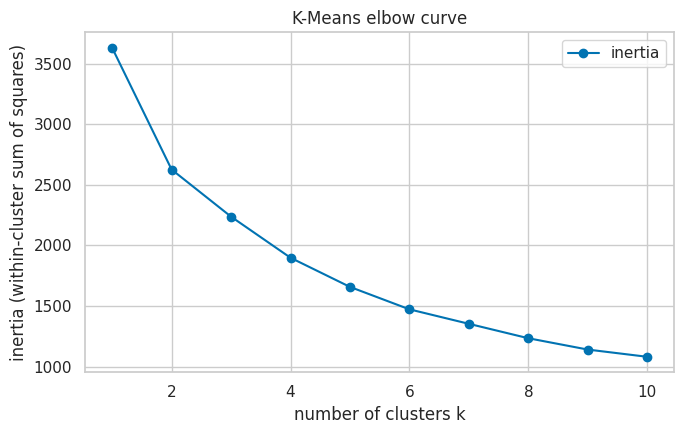

In [6]:
# elbow curve: inertia for k = 1..10
ks = range(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled).inertia_ for k in ks]

plt.figure(figsize=(7, 4.5))
plt.plot(list(ks), inertias, "o-", color=PALETTE[0], label="inertia")
plt.title("K-Means elbow curve")
plt.xlabel("number of clusters k")
plt.ylabel("inertia (within-cluster sum of squares)")
plt.legend()
plt.tight_layout()
plt.show()

**choice of k:** *(write your own: where the elbow bends and why you picked k)*

In [7]:
K_CHOSEN = 5    # chosen from the elbow curve above; change it if you read the elbow differently

kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=SEED).fit(X_scaled)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", np.bincount(km_labels).tolist())

K-Means cluster sizes: [120, 43, 6, 31, 42]


## 5. agglomerative hierarchical clustering

### 5.1 dendrograms for four linkage strategies

The dashed line marks the cut giving `K_CHOSEN` clusters, so both algorithms use the same k.

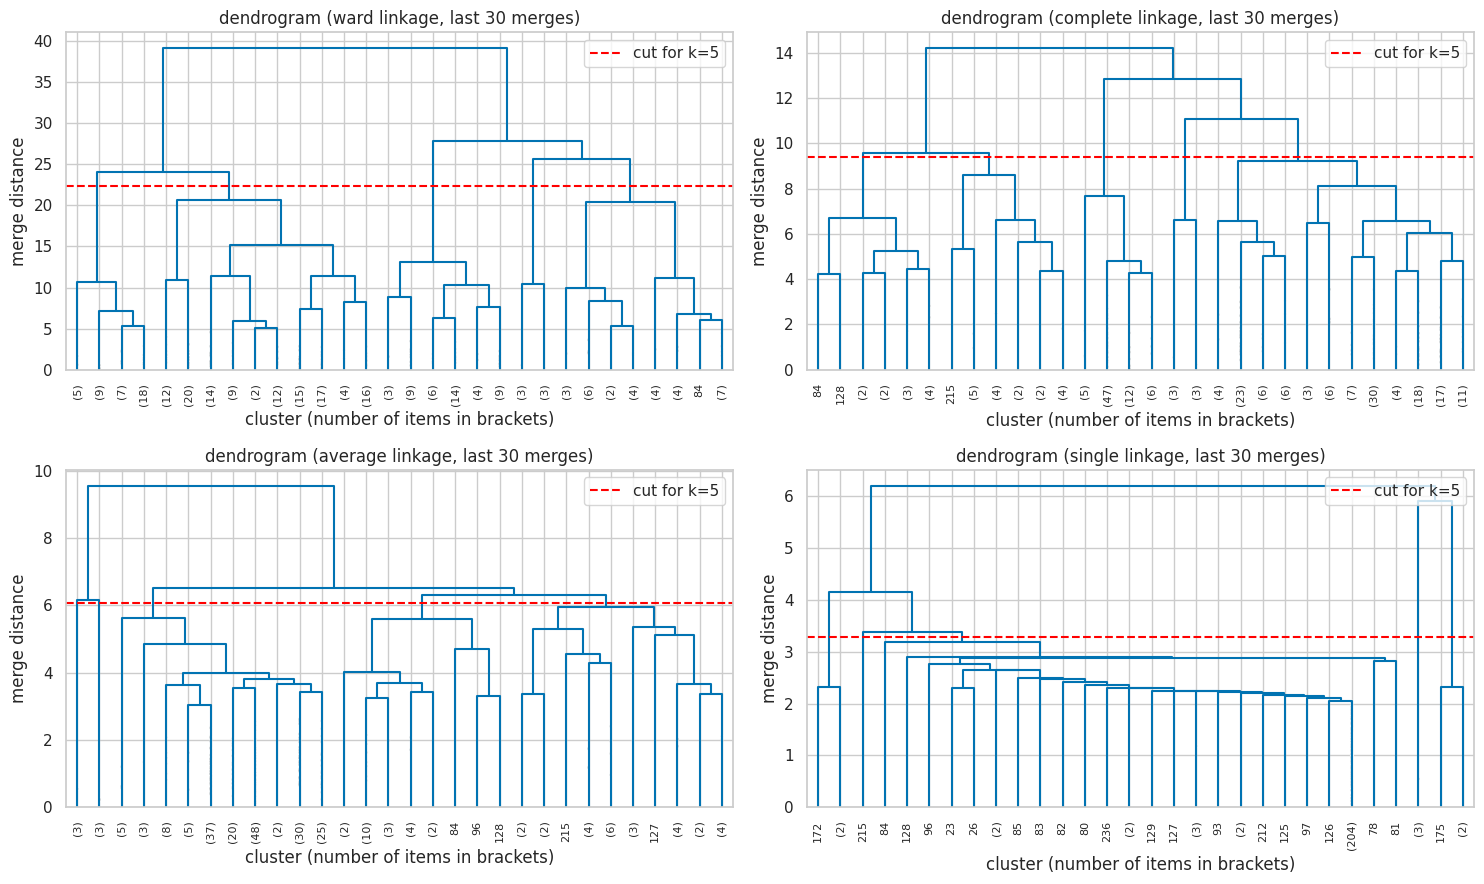

In [8]:
linkages = ["ward", "complete", "average", "single"]
Z = {m: linkage(X_scaled, method=m) for m in linkages}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.ravel(), linkages):
    dendrogram(Z[m], truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, color_threshold=0, above_threshold_color=PALETTE[0], ax=ax)
    cut = (Z[m][-K_CHOSEN, 2] + Z[m][-(K_CHOSEN - 1), 2]) / 2
    ax.axhline(cut, color="red", ls="--", label=f"cut for k={K_CHOSEN}")
    ax.set_title(f"dendrogram ({m} linkage, last 30 merges)")
    ax.set_xlabel("cluster (number of items in brackets)")
    ax.set_ylabel("merge distance")
    ax.legend()
plt.tight_layout()
plt.show()

### 5.2 comparing linkage strategies

In [9]:
link_rows = []
for m in linkages:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=m).fit_predict(X_scaled)
    link_rows.append({"Linkage": m, **cluster_metrics(X_scaled, lab),
                      "Cluster sizes": str(np.bincount(lab).tolist())})
display(pd.DataFrame(link_rows).set_index("Linkage").round(3))

HIER_LINKAGE = "ward"    # pick using the table above and justify it below
agg_labels = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=HIER_LINKAGE).fit_predict(X_scaled)
print("linkage used:", HIER_LINKAGE)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Linkage,,,,
ward,0.181,1.371,56.207,"[121, 31, 45, 6, 39]"
complete,0.143,1.437,49.927,"[135, 18, 70, 6, 13]"
average,0.361,1.041,47.987,"[29, 24, 183, 3, 3]"
single,0.289,0.604,11.945,"[232, 3, 3, 3, 1]"


linkage used: ward


**choice of linkage:** *(write your own: compare the linkages on the metrics and on the cluster sizes, then justify your choice)*

## 6. evaluation of all algorithms

Silhouette and Calinski-Harabasz: higher is better. Davies-Bouldin: lower is better.

In [10]:
results = {"K-Means": km_labels, f"Agglomerative ({HIER_LINKAGE})": agg_labels}

eval_df = pd.DataFrame([{"Algorithm": name, "Clusters": len(set(lab)),
                         **cluster_metrics(X_scaled, lab),
                         "Cluster sizes": str(np.bincount(lab).tolist())}
                        for name, lab in results.items()]).set_index("Algorithm")
display(eval_df.round(4))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Algorithm,,,,,
K-Means,5,0.2846,1.2741,70.5011,"[120, 43, 6, 31, 42]"
Agglomerative (ward),5,0.1809,1.3713,56.2067,"[121, 31, 45, 6, 39]"


**interpretation:** *(write your own: which algorithm is better on which metric, and what the scores say about cluster quality)*

## 7. cluster visualisation

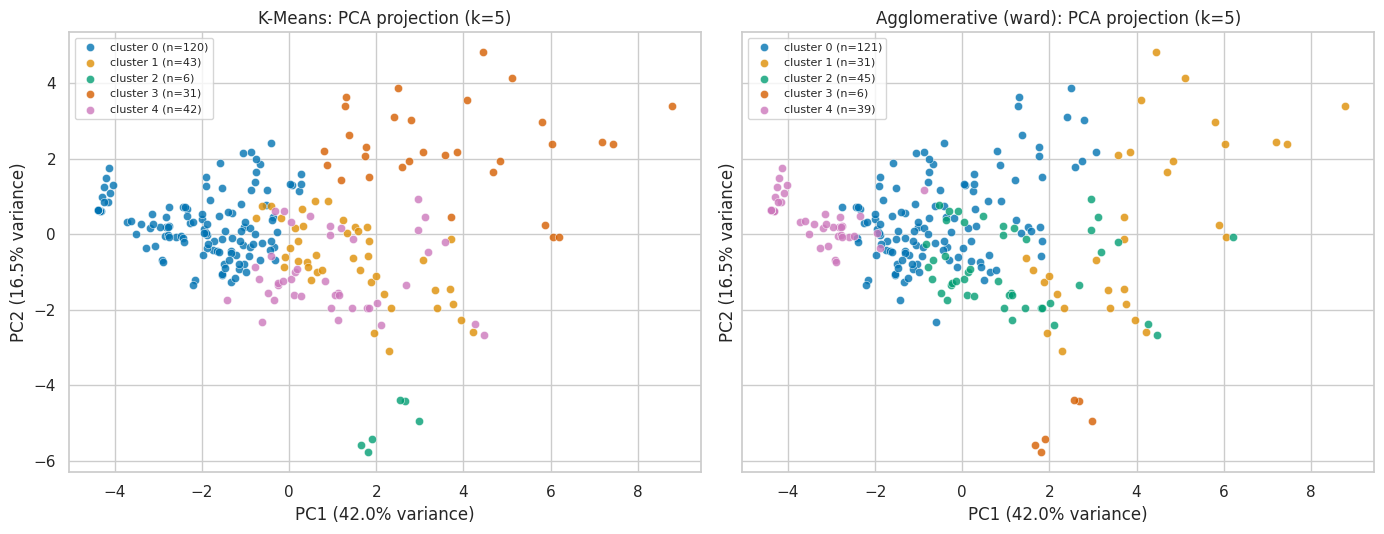

In [11]:
# PCA 2D scatter for every algorithm
fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, results.items()):
    plot_clusters(ax, X_pca, lab, f"{name}: PCA projection (k={K_CHOSEN})",
                  f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)")
plt.tight_layout()
plt.show()

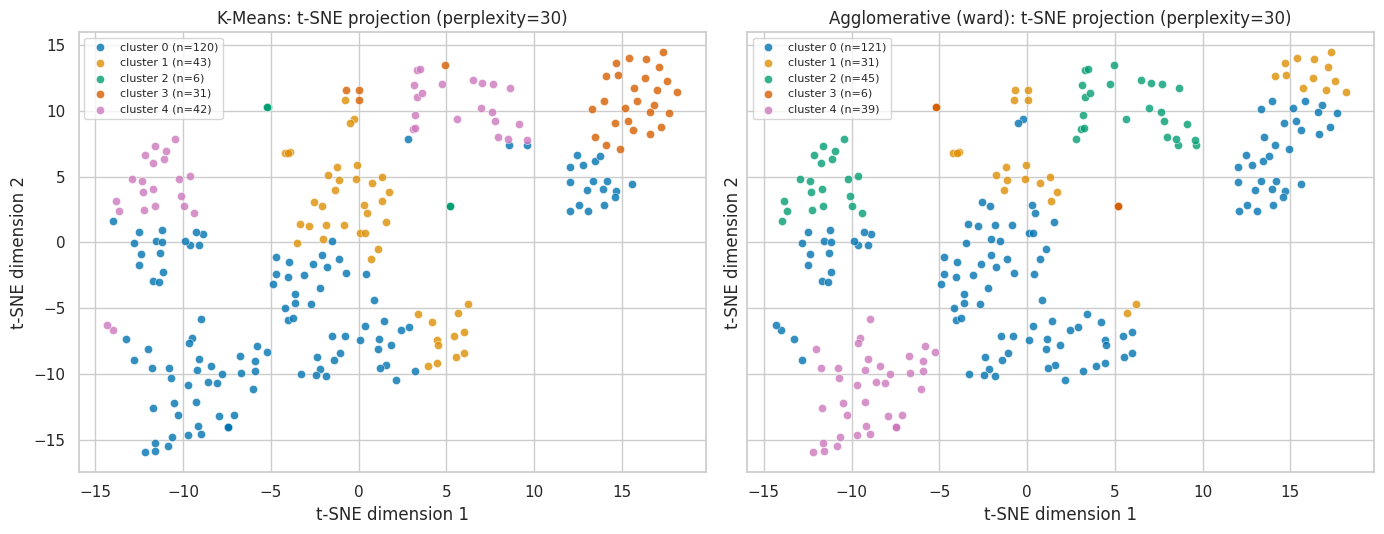

In [12]:
# t-SNE
perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
X_tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(X_scaled)

fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5), sharex=True, sharey=True)
for ax, (name, lab) in zip(axes, results.items()):
    plot_clusters(ax, X_tsne, lab, f"{name}: t-SNE projection (perplexity={perplexity})",
                  "t-SNE dimension 1", "t-SNE dimension 2")
plt.tight_layout()
plt.show()

**observation:** *(write your own: how well separated the clusters look, where they overlap)*

## 8. conclusion

*(Write in your own words: which algorithm gave the better clustering and why, and the trade-offs between K-Means and hierarchical clustering.)*